# Data Sanity Check

This notebook runs a series of checks on your pre-processed dataset to ensure its integrity before training. It verifies data types, value ranges, dimensions, and uniqueness of masks.

In [1]:
import os
import glob
import numpy as np
import tifffile
import hashlib
from tqdm import tqdm

# --- Configuration ---
# How many files to check from each set? Set to None to check all files.
SAMPLE_SIZE = None  # Check 20 images and 20 masks
ACCEPTED_SHAPES = [(1024, 1024), (1100, 1100), (1101, 1101)] # Now represents (H, W)
# -------------------

def get_file_hash(filepath):
    """Calculates the SHA256 hash of a file's content."""
    sha256_hash = hashlib.sha256()
    with open(filepath, "rb") as f:
        # Read and update hash in chunks to handle large files
        for byte_block in iter(lambda: f.read(4096), b""):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

### 1. Define Data Paths

First, we define the paths to our pre-processed training and validation sets. These are the same paths used in the training script.

In [6]:
# This should be the output directory from the `images_2_slices.py` script
DATA_PATH = r"/home/students/rawat/Final_dataset/DOG/"

# Define paths for the pre-split data
TRAIN_IMG_DIR = os.path.join(DATA_PATH, "train", "images")
TRAIN_LBL_DIR = os.path.join(DATA_PATH, "train", "masks")
VAL_IMG_DIR   = os.path.join(DATA_PATH, "validation", "images")
VAL_LBL_DIR   = os.path.join(DATA_PATH, "validation", "masks")

print(f"Training Image Directory: {TRAIN_IMG_DIR}")
print(f"Validation Image Directory: {VAL_IMG_DIR}")

Training Image Directory: /home/students/rawat/Final_dataset/DOG/train/images
Validation Image Directory: /home/students/rawat/Final_dataset/DOG/validation/images


### 2. Find All Image and Mask Files

Using `glob`, we gather all the file paths for our images and masks from both the training and validation directories.

In [7]:
# Get all the file paths
train_raw = sorted(glob.glob(os.path.join(TRAIN_IMG_DIR, "*.tif")))
train_lbl = sorted(glob.glob(os.path.join(TRAIN_LBL_DIR, "*.tif")))
val_raw   = sorted(glob.glob(os.path.join(VAL_IMG_DIR, "*.tif")))
val_lbl   = sorted(glob.glob(os.path.join(VAL_LBL_DIR, "*.tif")))

print(f"Found {len(train_raw)} training images and {len(train_lbl)} training masks.")
print(f"Found {len(val_raw)} validation images and {len(val_lbl)} validation masks.")

Found 9 training images and 9 training masks.
Found 2 validation images and 2 validation masks.


### 3. Image Sanity Check

This section iterates through a sample of image files and checks them for correctness.

**Checks performed:**
1.  **Data Type (`dtype`):** Must be `float32`.
2.  **Value Range:** All pixel values must be between 0.0 and 1.0.
3.  **Shape:** The image's (height, width, channels) must be one of the `ACCEPTED_SHAPES`.


In [8]:
print("--- Running Image Sanity Check ---")

# Combine train and validation images
all_images = train_raw + val_raw
files_to_check = all_images[:SAMPLE_SIZE] if SAMPLE_SIZE is not None else all_images

errors = []
shapes_found = {}
for img_path in tqdm(files_to_check, desc="Checking Images"):
    try:
        img = tifffile.imread(img_path)
        
        # Store shape
        shape = img.shape
        shapes_found[shape] = shapes_found.get(shape, 0) + 1
        
        # 1. Check dtype
        if img.dtype != 'float32':
            errors.append(f"FAILED DTYPE: {img_path} (is {img.dtype}, should be float32)")
            
        # 2. Check value range
        min_val, max_val = img.min(), img.max()
        if min_val < 0.0 or max_val > 1.0:
            # Add a small tolerance for floating point inaccuracies
            if not (np.isclose(min_val, 0.0) and np.isclose(max_val, 1.0)):
                 errors.append(f"FAILED RANGE: {img_path} (range is [{min_val:.2f}, {max_val:.2f}], should be [0.0, 1.0])")
            
        # 3. Check shape for 3D
        if img.ndim == 3: # For 3D images (D, H, W)
            h, w = img.shape[1], img.shape[2]
            if (h, w) not in ACCEPTED_SHAPES:
                errors.append(f"FAILED SHAPE: {img_path} (is {img.shape}, H,W should be in {ACCEPTED_SHAPES})")
        elif img.ndim == 4: # For 3D images with channels (D, H, W, C)
            h, w = img.shape[1], img.shape[2]
            if (h, w) not in ACCEPTED_SHAPES:
                errors.append(f"FAILED SHAPE: {img_path} (is {img.shape}, H,W should be in {ACCEPTED_SHAPES})")
        else:
            errors.append(f"FAILED SHAPE: {img_path} (is {img.shape}, not a 3D or 4D image)")


    except Exception as e:
        errors.append(f"FAILED TO READ: {img_path} ({e})")

# --- Reporting ---

# Report on shapes found
print("\n--- Image Shape Report ---")
if shapes_found:
    print("Found the following shapes in the dataset:")
    for shape, count in shapes_found.items():
        print(f"  - Shape: {shape}, Count: {count}")
else:
    print("No images were checked.")


if not errors:
    print("\n✅ All checked images passed the sanity check!")
else:
    print("\n❌ Errors found in images:")
    for error in errors:
        print(f"  - {error}")

--- Running Image Sanity Check ---


Checking Images: 100%|██████████| 11/11 [00:01<00:00,  7.48it/s]


--- Image Shape Report ---
Found the following shapes in the dataset:
  - Shape: (53, 2, 1100, 1100), Count: 1
  - Shape: (40, 2, 1100, 1100), Count: 1
  - Shape: (38, 2, 1100, 1100), Count: 1
  - Shape: (48, 2, 1100, 1100), Count: 1
  - Shape: (75, 2, 1101, 1101), Count: 1
  - Shape: (56, 2, 1101, 1101), Count: 1
  - Shape: (36, 2, 1101, 1101), Count: 1
  - Shape: (45, 2, 1101, 1101), Count: 1
  - Shape: (38, 2, 1101, 1101), Count: 1
  - Shape: (43, 2, 1100, 1100), Count: 1
  - Shape: (52, 2, 1101, 1101), Count: 1

❌ Errors found in images:
  - FAILED RANGE: /home/students/rawat/Final_dataset/DOG/train/images/Brain4_1340_Cont_AiryscanSR_Fly2_CalyxR_1100.tif (range is [0.00, 244.93], should be [0.0, 1.0])
  - FAILED SHAPE: /home/students/rawat/Final_dataset/DOG/train/images/Brain4_1340_Cont_AiryscanSR_Fly2_CalyxR_1100.tif (is (53, 2, 1100, 1100), H,W should be in [(1024, 1024), (1100, 1100), (1101, 1101)])
  - FAILED RANGE: /home/students/rawat/Final_dataset/DOG/train/images/Brain5_13

### 4. Mask Sanity Check

This section checks the masks.

**Checks performed:**
1.  **Data Type (`dtype`):** Must be an integer type (e.g., `uint16`, `int32`).
2.  **Shape:** The mask's (height, width) must match the corresponding image shapes (ignoring the channel dimension).
3.  **Uniqueness:** Checks if different mask files have unique content by comparing their file hashes.


In [9]:
print("\n--- Running Mask Sanity Check ---")

all_masks = train_lbl + val_lbl
files_to_check = all_masks[:SAMPLE_SIZE] if SAMPLE_SIZE is not None else all_masks

errors = []
mask_hashes = set()
for mask_path in tqdm(files_to_check, desc="Checking Masks"):
    try:
        mask = tifffile.imread(mask_path)
        
        # 1. Check dtype
        if not np.issubdtype(mask.dtype, np.integer):
            errors.append(f"FAILED DTYPE: {mask_path} (is {mask.dtype}, should be an integer type)")
            
        # 2. Check shape for 3D
        if mask.ndim == 3: # For 3D masks (D, H, W)
            h, w = mask.shape[1], mask.shape[2]
            if (h, w) not in ACCEPTED_SHAPES:
                errors.append(f"FAILED SHAPE: {mask_path} (is {mask.shape}, H,W should be in {ACCEPTED_SHAPES})")
        else:
            errors.append(f"FAILED SHAPE: {mask_path} (is {mask.shape}, not a 3D mask)")
        
        # 3. Check for uniqueness
        file_hash = get_file_hash(mask_path)
        if file_hash in mask_hashes:
            errors.append(f"FAILED UNIQUENESS: {mask_path} has the same content as a previously checked mask.")
        mask_hashes.add(file_hash)

    except Exception as e:
        errors.append(f"FAILED TO READ: {mask_path} ({e})")

if not errors:
    print("\n✅ All checked masks passed the sanity check!")
else:
    print("\n❌ Errors found in masks:")
    for error in errors:
        print(f"  - {error}")


--- Running Mask Sanity Check ---


Checking Masks: 100%|██████████| 11/11 [00:01<00:00,  7.52it/s]


✅ All checked masks passed the sanity check!


### 4a. Check for Empty Masks

This check iterates through the mask files to find any that are completely empty (all pixel values are 0). This is useful for identifying masks that may have been generated incorrectly or that correspond to images with no objects of interest.


In [6]:
print("\n--- Checking for Empty Masks ---")

empty_masks = []
for mask_path in tqdm(all_masks, desc="Checking for empty masks"):
    try:
        mask = tifffile.imread(mask_path)
        if mask.max() == 0:
            empty_masks.append(mask_path)
    except Exception as e:
        print(f"Could not read {mask_path}: {e}")

if not empty_masks:
    print("\n✅ No empty masks found.")
else:
    print(f"\n❌ Found {len(empty_masks)} empty masks:")
    for path in empty_masks:
        print(f"  - {path}")



--- Checking for Empty Masks ---


Checking for empty masks: 100%|██████████| 11/11 [00:01<00:00,  6.95it/s]


✅ No empty masks found.


### 5. File Mapping Verification

This check ensures that for every image file in the training and validation sets, there is a corresponding mask file with the exact same base name. This is crucial for the data loader to correctly pair images and their labels.


In [10]:
print("\n--- Running File Mapping Verification ---")

errors = []
all_image_files = train_raw + val_raw
all_mask_files = train_lbl + val_lbl

# Check if the number of images and masks match
if len(all_image_files) != len(all_mask_files):
    errors.append(f"Mismatch in file counts: {len(all_image_files)} images vs {len(all_mask_files)} masks.")

# Check for 1-to-1 mapping
for img_path, mask_path in tqdm(zip(all_image_files, all_mask_files), total=len(all_image_files), desc="Verifying file pairs"):
    img_name = os.path.basename(img_path)
    mask_name = os.path.basename(mask_path)
    if img_name != mask_name:
        errors.append(f"Mismatch found: Image '{img_name}' is paired with Mask '{mask_name}'")

if not errors:
    print("\n✅ All image and mask files are perfectly paired!")
else:
    print("\n❌ Errors found in file mapping:")
    for error in errors:
        print(f"  - {error}")



--- Running File Mapping Verification ---


Verifying file pairs: 100%|██████████| 11/11 [00:00<00:00, 135698.07it/s]


❌ Errors found in file mapping:
  - Mismatch found: Image 'Brain4_1340_Cont_AiryscanSR_Fly2_CalyxR_1100.tif' is paired with Mask 'Brain4_1340_Cont_AiryscanSR_Fly2_CalyxR_1100_mask.tif'
  - Mismatch found: Image 'Brain5_1340_Cont_AiryscanSR_Fly3_CalyxR_1100.tif' is paired with Mask 'Brain5_1340_Cont_AiryscanSR_Fly3_CalyxR_1100_mask.tif'
  - Mismatch found: Image 'Brain6_1340_MTM_AiryscanSR_Fly3_CalyxL_1100.tif' is paired with Mask 'Brain6_1340_MTM_AiryscanSR_Fly3_CalyxL_1100_mask.tif'
  - Mismatch found: Image 'Brain7_1340_MTM_AiryscanSR_Fly3_CalyxR_1100.tif' is paired with Mask 'Brain7_1340_MTM_AiryscanSR_Fly3_CalyxR_1100_mask.tif'
  - Mismatch found: Image 'PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit_dog.tif' is paired with Mask 'PN_KC_488_568_Brain1_CalyxL_LSMPlus_16bit_mask.tif'
  - Mismatch found: Image 'PN_KC_488_568_Brain1_CalyxR_LSMPlus_16bit_dog.tif' is paired with Mask 'PN_KC_488_568_Brain1_CalyxR_LSMPlus_16bit_mask.tif'
  - Mismatch found: Image 'PN_KC_488_568_Brain4_CalyxL_LS

### 6. Augmentation Visualization

This final check visualizes the effect of the data augmentation pipeline on a sample image and mask. It confirms that:
1.  Intensity augmentations are applied only to the image.
2.  Geometric augmentations are applied identically to both the image and the mask, preserving their alignment.



Volume 1: Brain7_1340_MTM_AiryscanSR_Fly3_CalyxR_1100.tif
  [fix] Transposed from (Z,C,Y,X) → (Z,Y,X,C): (48, 1100, 1100, 2)


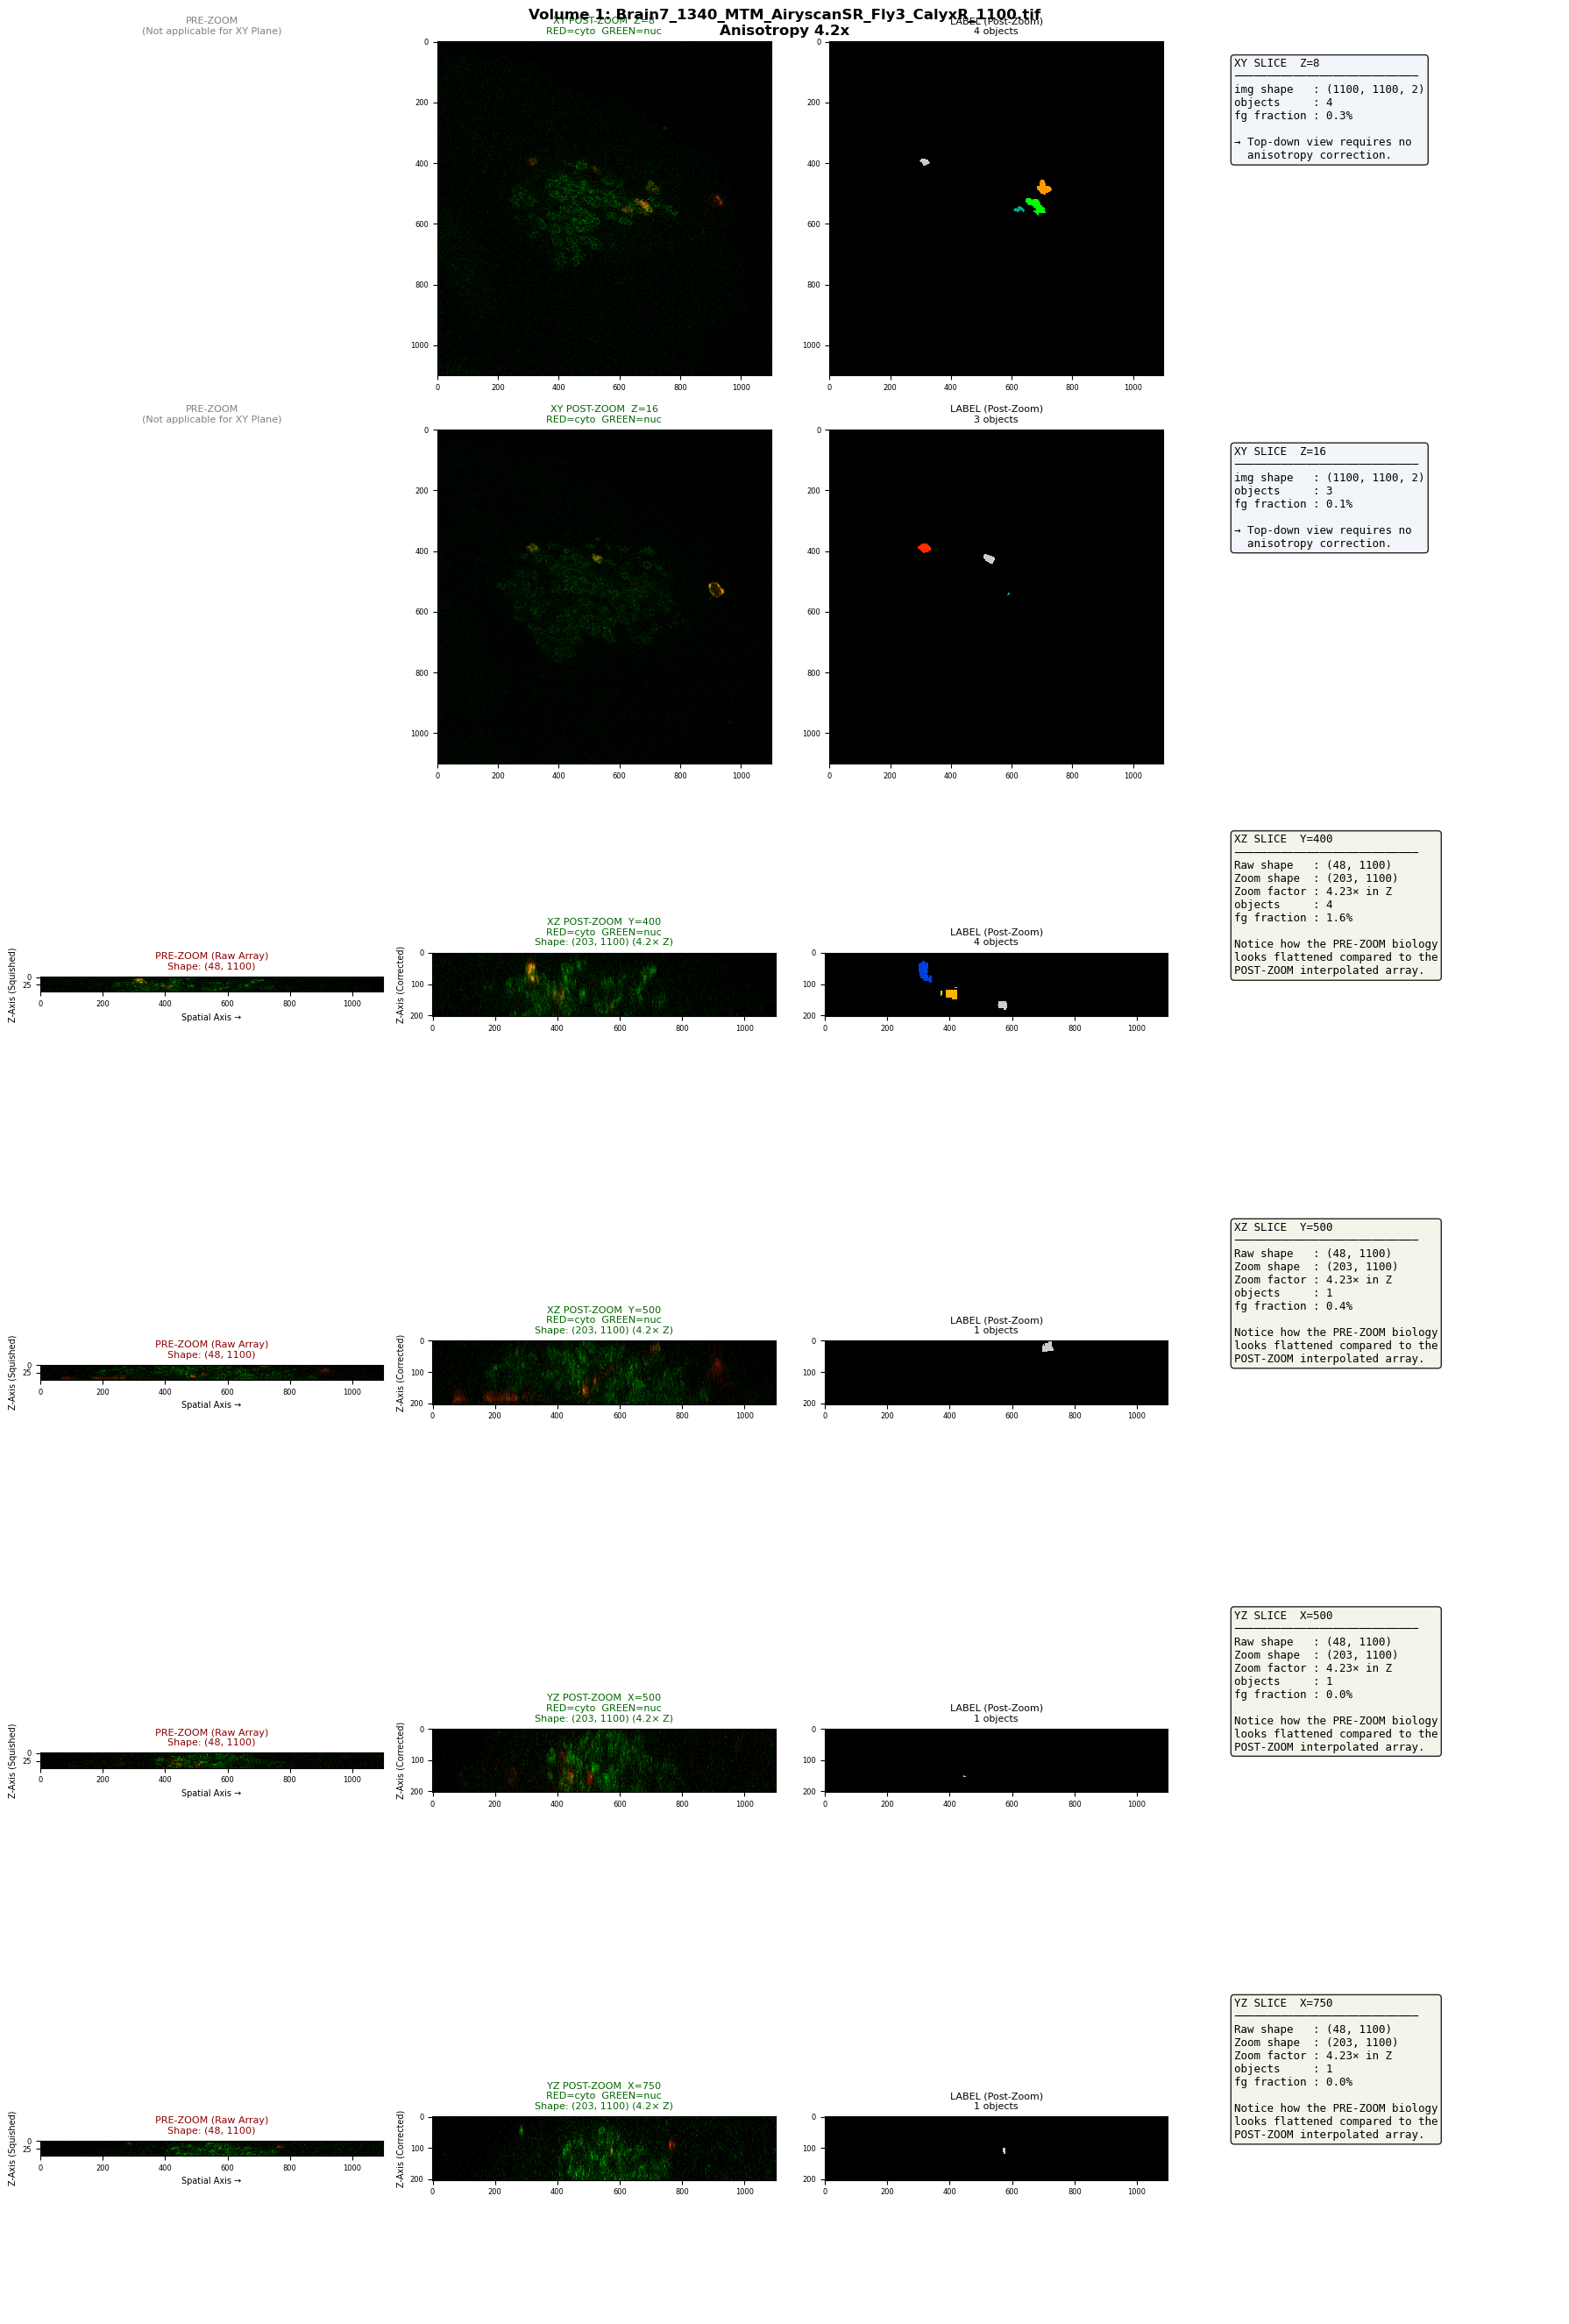


Volume 2: PN_KC_488_568_Brain5_CalyxL_LSMPlus_16bit_dog.tif
  [fix] Transposed from (Z,C,Y,X) → (Z,Y,X,C): (38, 1101, 1101, 2)


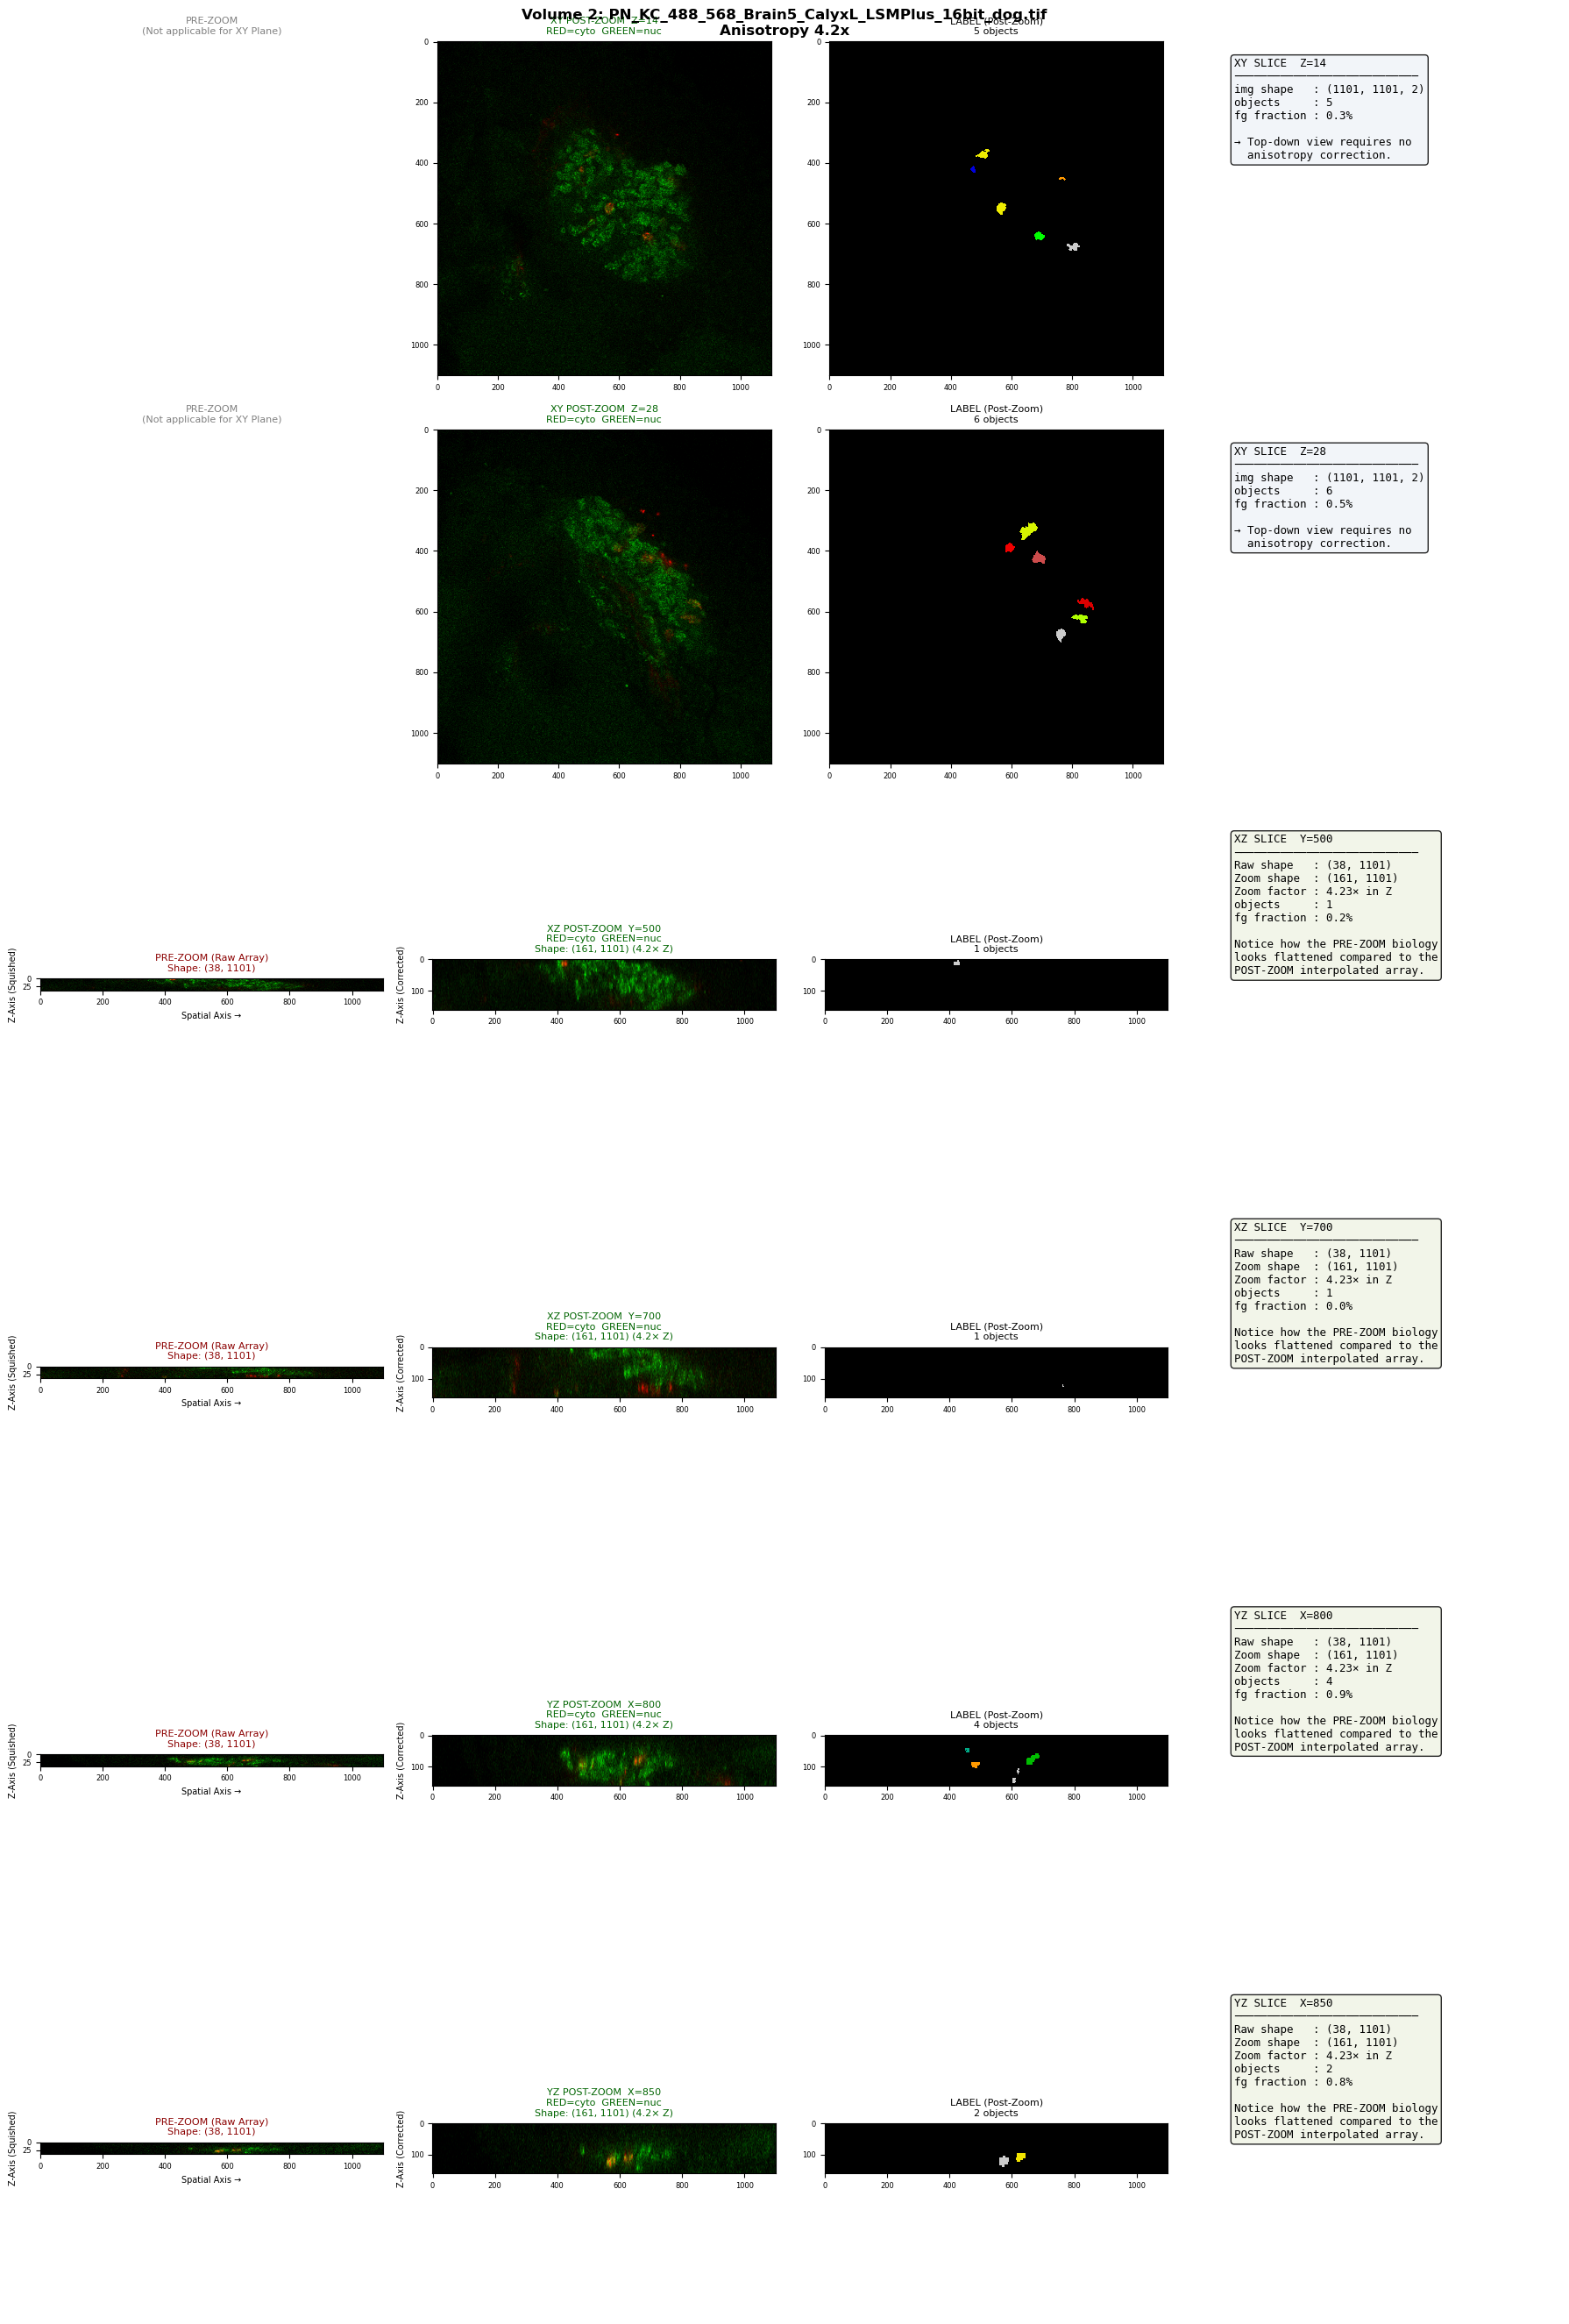

In [12]:
"""
Cell 16 — Cellpose3D Pipeline Visualization (v5 Before/After Zoom)
==================================================================
Fixes:
  - Added 4th column to visually compare Pre-Zoom vs Post-Zoom side-by-side.
  - Retains all previous (Z, C, Y, X) shape guards and 1-99 normalization.
"""

import tifffile
import numpy as np
import matplotlib.pyplot as plt
import random
from scipy.ndimage import zoom
from pathlib import Path

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────────────────────
CELLPOSE_CONFIG = {
    "IMAGE_POSTFIXES": ["_dog", "_deconv", "_100"],
    "LABEL_POSTFIX":   "_mask.tif",
    "CHANNEL_IDX":     0,
    "NUCLEUS_IDX":     1,
    "XY_VOXEL_UM":    0.0709,
    "Z_VOXEL_UM":     0.3,
    "XZ_YZ_STRIDE":   50,
}

# ─────────────────────────────────────────────────────────────────────────────
# Pipeline functions
# ─────────────────────────────────────────────────────────────────────────────
def fix_image_dims(img):
    if img.ndim == 2: return img[np.newaxis, ..., np.newaxis]
    if img.ndim == 3: return img[..., np.newaxis]
    if img.ndim == 4:
        if int(np.argmin(img.shape)) == 0:
            img = np.transpose(img, (1, 2, 3, 0))
    return img

def ensure_zyxc(img):
    if img.ndim == 4 and img.shape[1] <= 4 and img.shape[1] < img.shape[2]:
        img = np.transpose(img, (0, 2, 3, 1))
        print(f"  [fix] Transposed from (Z,C,Y,X) → (Z,Y,X,C): {img.shape}")
    return img

def fix_label_dims(lbl):
    if lbl.ndim == 4: lbl = lbl.squeeze()
    if lbl.ndim == 2: lbl = lbl[np.newaxis]
    return lbl.astype(np.int32)

def select_channels(img, channel_idx, nucleus_idx):
    if img.ndim == 3: return img[..., np.newaxis]
    cyto = img.mean(axis=-1, keepdims=True) if channel_idx is None else img[..., [channel_idx]]
    if nucleus_idx is not None and nucleus_idx < img.shape[-1]:
        return np.concatenate([cyto, img[..., [nucleus_idx]]], axis=-1)
    return cyto

def normalize_slice(sl):
    sl = sl.astype(np.float32)
    for c in range(sl.shape[-1]):
        lo, hi = np.percentile(sl[..., c], (0.00001, 99.99999))
        sl[..., c] = (sl[..., c] - lo) / (hi - lo) if hi > lo else 0.0
    return np.clip(sl, 0.0, 1.0)

# ─────────────────────────────────────────────────────────────────────────────
# Display helpers
# ─────────────────────────────────────────────────────────────────────────────
def to_display_rgb(arr_hwc):
    arr = np.clip(arr_hwc.astype(np.float32), 0, 1)
    if arr.ndim == 2 or arr.shape[-1] == 1:
        g = arr.squeeze()
        return np.stack([g, g, g], axis=-1)
    if arr.shape[-1] == 2:
        return np.stack([arr[..., 0], arr[..., 1], np.zeros_like(arr[..., 0])], axis=-1)
    return arr[..., :3]

def label_to_rgb(lbl):
    lbl = lbl.astype(float)
    mx  = lbl.max()
    if mx == 0: return np.zeros((*lbl.shape, 3), dtype=np.float32)
    col = plt.cm.nipy_spectral(lbl / mx)[..., :3].astype(np.float32)
    col[lbl == 0] = 0
    return col

def find_label_path(img_path, label_dir, cfg):
    base = Path(img_path).stem
    for postfix in cfg["IMAGE_POSTFIXES"]:
        if base.endswith(postfix):
            base = base[: -len(postfix)]
            break
    for candidate in [Path(label_dir) / (base + cfg["LABEL_POSTFIX"]), Path(label_dir) / (Path(img_path).stem + "_mask.tif")]:
        if candidate.exists(): return str(candidate)
    return None

# ─────────────────────────────────────────────────────────────────────────────
# Schedulers
# ─────────────────────────────────────────────────────────────────────────────
def valid_xy(lbl_zyx): return [z for z in range(lbl_zyx.shape[0]) if lbl_zyx[z].max() > 0]
def valid_xz(lbl_zyx, stride): return [y for y in range(0, lbl_zyx.shape[1], stride) if lbl_zyx[:, y, :].max() > 0]
def valid_yz(lbl_zyx, stride): return [x for x in range(0, lbl_zyx.shape[2], stride) if lbl_zyx[:, :, x].max() > 0]

# ─────────────────────────────────────────────────────────────────────────────
# Extractors (Now returning BOTH Raw and Zoomed arrays)
# ─────────────────────────────────────────────────────────────────────────────
def get_xy(img_sel, lbl_zyx, z):
    img_norm = normalize_slice(img_sel[z])
    # XY doesn't zoom, so raw and zoomed are identical
    return img_norm, img_norm, lbl_zyx[z]

def get_xz(img_sel, lbl_zyx, y, aniso):
    xz_img_raw = img_sel[:, y, :, :].astype(np.float32)
    xz_lbl_raw = lbl_zyx[:, y, :]
    xz_img_zoom = zoom(xz_img_raw, (aniso, 1.0, 1.0), order=1).astype(np.float32)
    xz_lbl_zoom = zoom(xz_lbl_raw, (aniso, 1.0), order=0).astype(np.int32)
    return normalize_slice(xz_img_raw), normalize_slice(xz_img_zoom), xz_lbl_zoom

def get_yz(img_sel, lbl_zyx, x, aniso):
    yz_img_raw = img_sel[:, :, x, :].astype(np.float32)
    yz_lbl_raw = lbl_zyx[:, :, x]
    yz_img_zoom = zoom(yz_img_raw, (aniso, 1.0, 1.0), order=1).astype(np.float32)
    yz_lbl_zoom = zoom(yz_lbl_raw, (aniso, 1.0), order=0).astype(np.int32)
    return normalize_slice(yz_img_raw), normalize_slice(yz_img_zoom), yz_lbl_zoom

# ─────────────────────────────────────────────────────────────────────────────
# Plot Row (Now heavily modified for 4 columns)
# ─────────────────────────────────────────────────────────────────────────────
def plot_row(axes_row, img_raw, img_zoom, lbl, plane, idx_label, shape_before, shape_after, aniso, n_ch):
    is_aniso  = plane in ("XZ", "YZ")
    n_objects = len(np.unique(lbl)) - 1
    fg_frac   = (lbl > 0).mean() * 100
    ch_note   = "RED=cyto  GREEN=nuc" if n_ch == 2 else "greyscale"

    # Column 0: Pre-Zoom Image (Only for XZ/YZ)
    if is_aniso:
        axes_row[0].imshow(to_display_rgb(img_raw), aspect='equal', interpolation='nearest')
        axes_row[0].set_title(f"PRE-ZOOM (Raw Array)\nShape: {shape_before}", fontsize=8, color='darkred')
        axes_row[0].set_ylabel("Z-Axis (Squished)", fontsize=7)
        axes_row[0].set_xlabel("Spatial Axis →", fontsize=7)
        axes_row[0].tick_params(labelsize=6)
    else:
        axes_row[0].axis('off')
        axes_row[0].set_title("PRE-ZOOM\n(Not applicable for XY Plane)", fontsize=8, color='gray')

    # Column 1: Post-Zoom Image
    axes_row[1].imshow(to_display_rgb(img_zoom), aspect='equal', interpolation='nearest')
    title_zoom = f"{plane} POST-ZOOM  {idx_label}\n{ch_note}"
    if is_aniso: title_zoom += f"\nShape: {shape_after} ({aniso:.1f}× Z)"
    axes_row[1].set_title(title_zoom, fontsize=8, color='darkgreen')
    if is_aniso: axes_row[1].set_ylabel("Z-Axis (Corrected)", fontsize=7)
    axes_row[1].tick_params(labelsize=6)

    # Column 2: Label
    axes_row[2].imshow(label_to_rgb(lbl), aspect='equal', interpolation='nearest')
    axes_row[2].set_title(f"LABEL (Post-Zoom)\n{n_objects} objects", fontsize=8)
    axes_row[2].tick_params(labelsize=6)

    # Column 3: Stats
    if is_aniso:
        stats = (
            f"{plane} SLICE  {idx_label}\n{'─'*28}\n"
            f"Raw shape   : {shape_before}\n"
            f"Zoom shape  : {shape_after}\n"
            f"Zoom factor : {aniso:.2f}× in Z\n"
            f"objects     : {n_objects}\n"
            f"fg fraction : {fg_frac:.1f}%\n\n"
            f"Notice how the PRE-ZOOM biology\n"
            f"looks flattened compared to the\n"
            f"POST-ZOOM interpolated array."
        )
        bg = '#f0f4e6'
    else:
        stats = (
            f"{plane} SLICE  {idx_label}\n{'─'*28}\n"
            f"img shape   : {img_zoom.shape}\n"
            f"objects     : {n_objects}\n"
            f"fg fraction : {fg_frac:.1f}%\n\n"
            f"→ Top-down view requires no\n"
            f"  anisotropy correction."
        )
        bg = '#f0f4f8'

    axes_row[3].text(
        0.05, 0.95, stats, transform=axes_row[3].transAxes,
        fontsize=9, verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor=bg, alpha=0.85)
    )
    axes_row[3].axis('off')

# ─────────────────────────────────────────────────────────────────────────────
# Main Loop
# ─────────────────────────────────────────────────────────────────────────────
def visualize_cellpose3d_pipeline(image_paths, label_paths, cfg, num_volumes=2, xy_slices=2, xz_slices=2, yz_slices=2):
    label_dir = str(Path(label_paths[0]).parent)
    aniso     = cfg["Z_VOXEL_UM"] / cfg["XY_VOXEL_UM"]
    stride    = cfg.get("XZ_YZ_STRIDE", 50)

    indices = random.sample(range(len(image_paths)), min(num_volumes, len(image_paths)))

    for vol_num, idx in enumerate(indices):
        img_path = image_paths[idx]
        lbl_path = find_label_path(img_path, label_dir, cfg)

        print(f"\n{'='*60}\nVolume {vol_num+1}: {Path(img_path).name}")
        if not lbl_path:
            print("  [SKIP] label not found.")
            continue

        raw_img, raw_lbl = tifffile.imread(img_path), tifffile.imread(lbl_path)
        img_fixed = ensure_zyxc(fix_image_dims(raw_img.copy()))
        lbl_zyx   = fix_label_dims(raw_lbl.copy())
        img_sel   = ensure_zyxc(select_channels(img_fixed, cfg["CHANNEL_IDX"], cfg["NUCLEUS_IDX"]))
        n_ch      = img_sel.shape[-1]

        v_xy = valid_xy(lbl_zyx)
        v_xz = valid_xz(lbl_zyx, stride)
        v_yz = valid_yz(lbl_zyx, stride)

        xy_show = sorted(random.sample(v_xy, min(xy_slices, len(v_xy)))) if v_xy else []
        xz_show = sorted(random.sample(v_xz, min(xz_slices, len(v_xz)))) if v_xz else []
        yz_show = sorted(random.sample(v_yz, min(yz_slices, len(v_yz)))) if v_yz else []

        total_rows = len(xy_show) + len(xz_show) + len(yz_show)
        if total_rows == 0: continue

        # Changed to 4 columns, slightly wider figure
        fig, axes = plt.subplots(total_rows, 4, figsize=(18, 4.5 * total_rows), squeeze=False)
        fig.suptitle(f"Volume {vol_num+1}: {Path(img_path).name}\nAnisotropy {aniso:.1f}x", fontsize=12, fontweight='bold')

        row = 0
        for z in xy_show:
            img_raw, img_zoom, lbl = get_xy(img_sel, lbl_zyx, z)
            plot_row(axes[row], img_raw, img_zoom, lbl, "XY", f"Z={z}", img_raw.shape[:2], img_zoom.shape[:2], aniso, n_ch)
            row += 1

        for y in xz_show:
            sb = img_sel[:, y, :, :].shape[:2]
            img_raw, img_zoom, lbl = get_xz(img_sel, lbl_zyx, y, aniso)
            plot_row(axes[row], img_raw, img_zoom, lbl, "XZ", f"Y={y}", sb, img_zoom.shape[:2], aniso, n_ch)
            row += 1

        for x in yz_show:
            sb = img_sel[:, :, x, :].shape[:2]
            img_raw, img_zoom, lbl = get_yz(img_sel, lbl_zyx, x, aniso)
            plot_row(axes[row], img_raw, img_zoom, lbl, "YZ", f"X={x}", sb, img_zoom.shape[:2], aniso, n_ch)
            row += 1

        plt.tight_layout()
        plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# Run
# ─────────────────────────────────────────────────────────────────────────────
visualize_cellpose3d_pipeline(
    train_raw, 
    train_lbl, 
    CELLPOSE_CONFIG, 
    num_volumes=2, 
    xy_slices=2, 
    xz_slices=2, 
    yz_slices=2
)

### 7. Validation Set Visualization

This is the same visualization as above, but it runs on the **validation set** (`val_raw`, `val_lbl`) instead of the training set. This is useful for a final sanity check on the data that will be used for evaluating model performance.


Volume 1: PN_KC_488_568_Brain3_CalyxL_LSMPlus_16bit_dog.tif
  [fix] Transposed from (Z,C,Y,X) → (Z,Y,X,C): (52, 1101, 1101, 2)


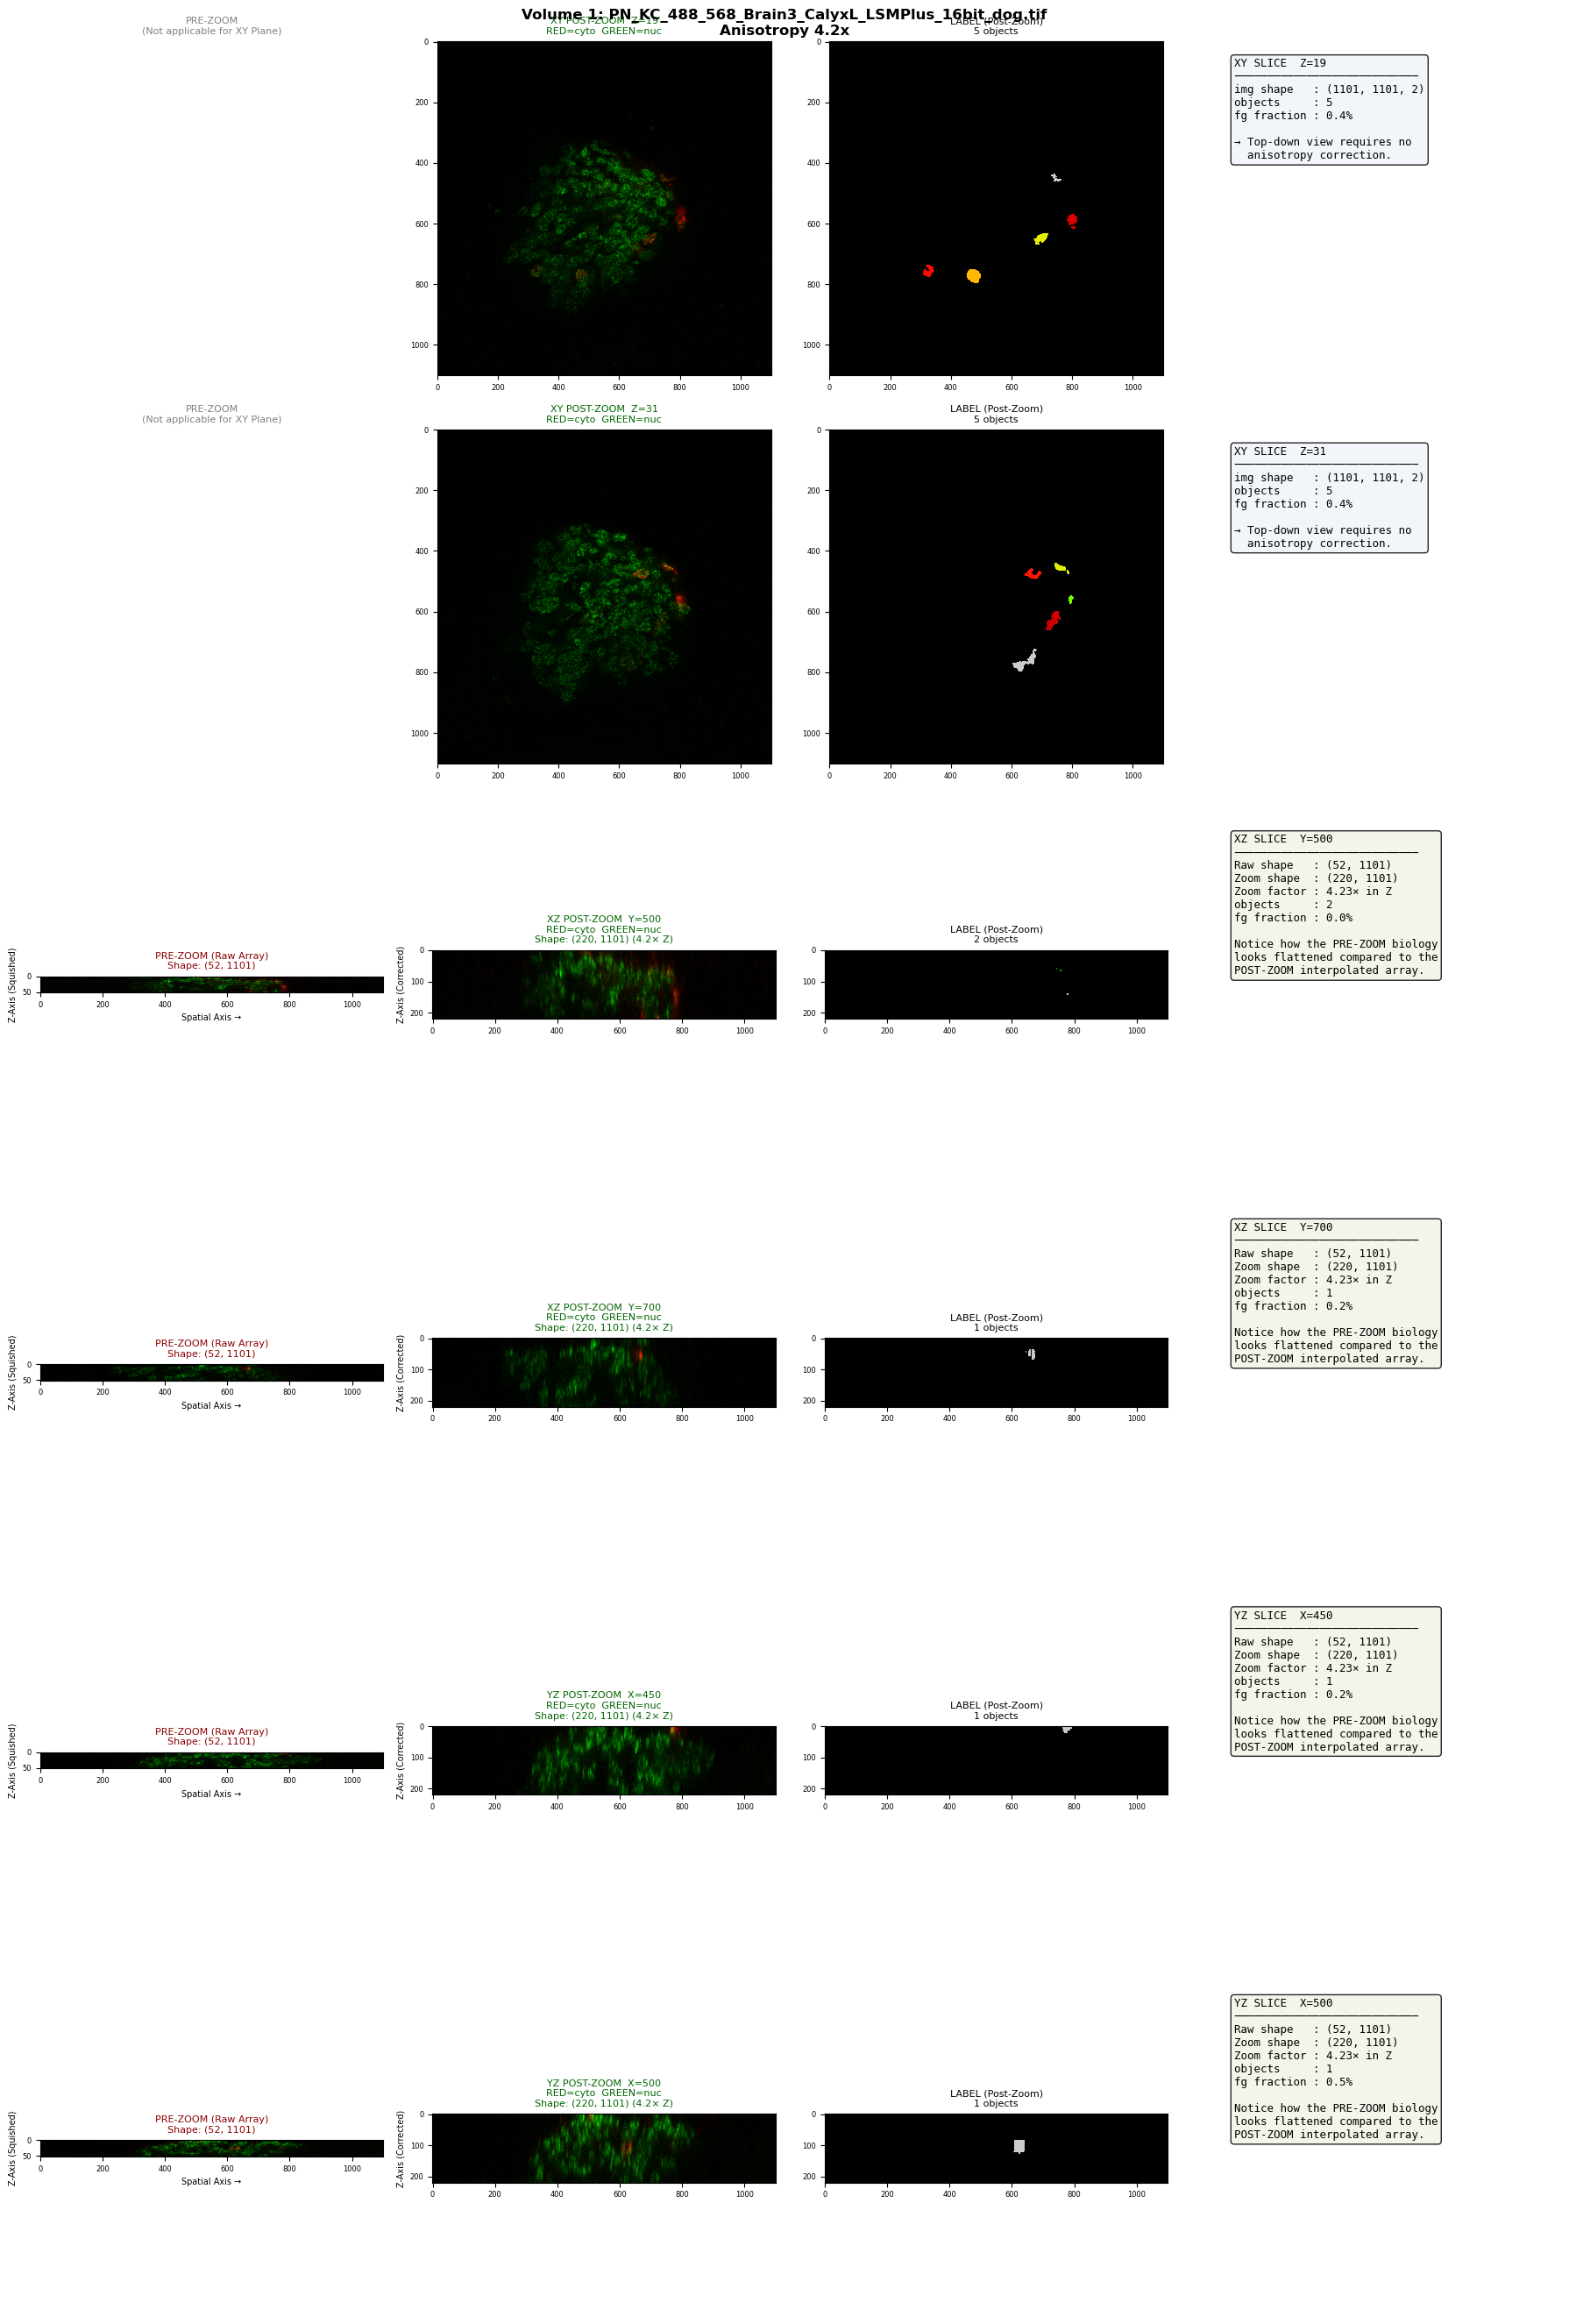


Volume 2: Brain2_1340_Cont_AiryscanSR_Fly1_CalyxR_1100.tif
  [fix] Transposed from (Z,C,Y,X) → (Z,Y,X,C): (43, 1100, 1100, 2)


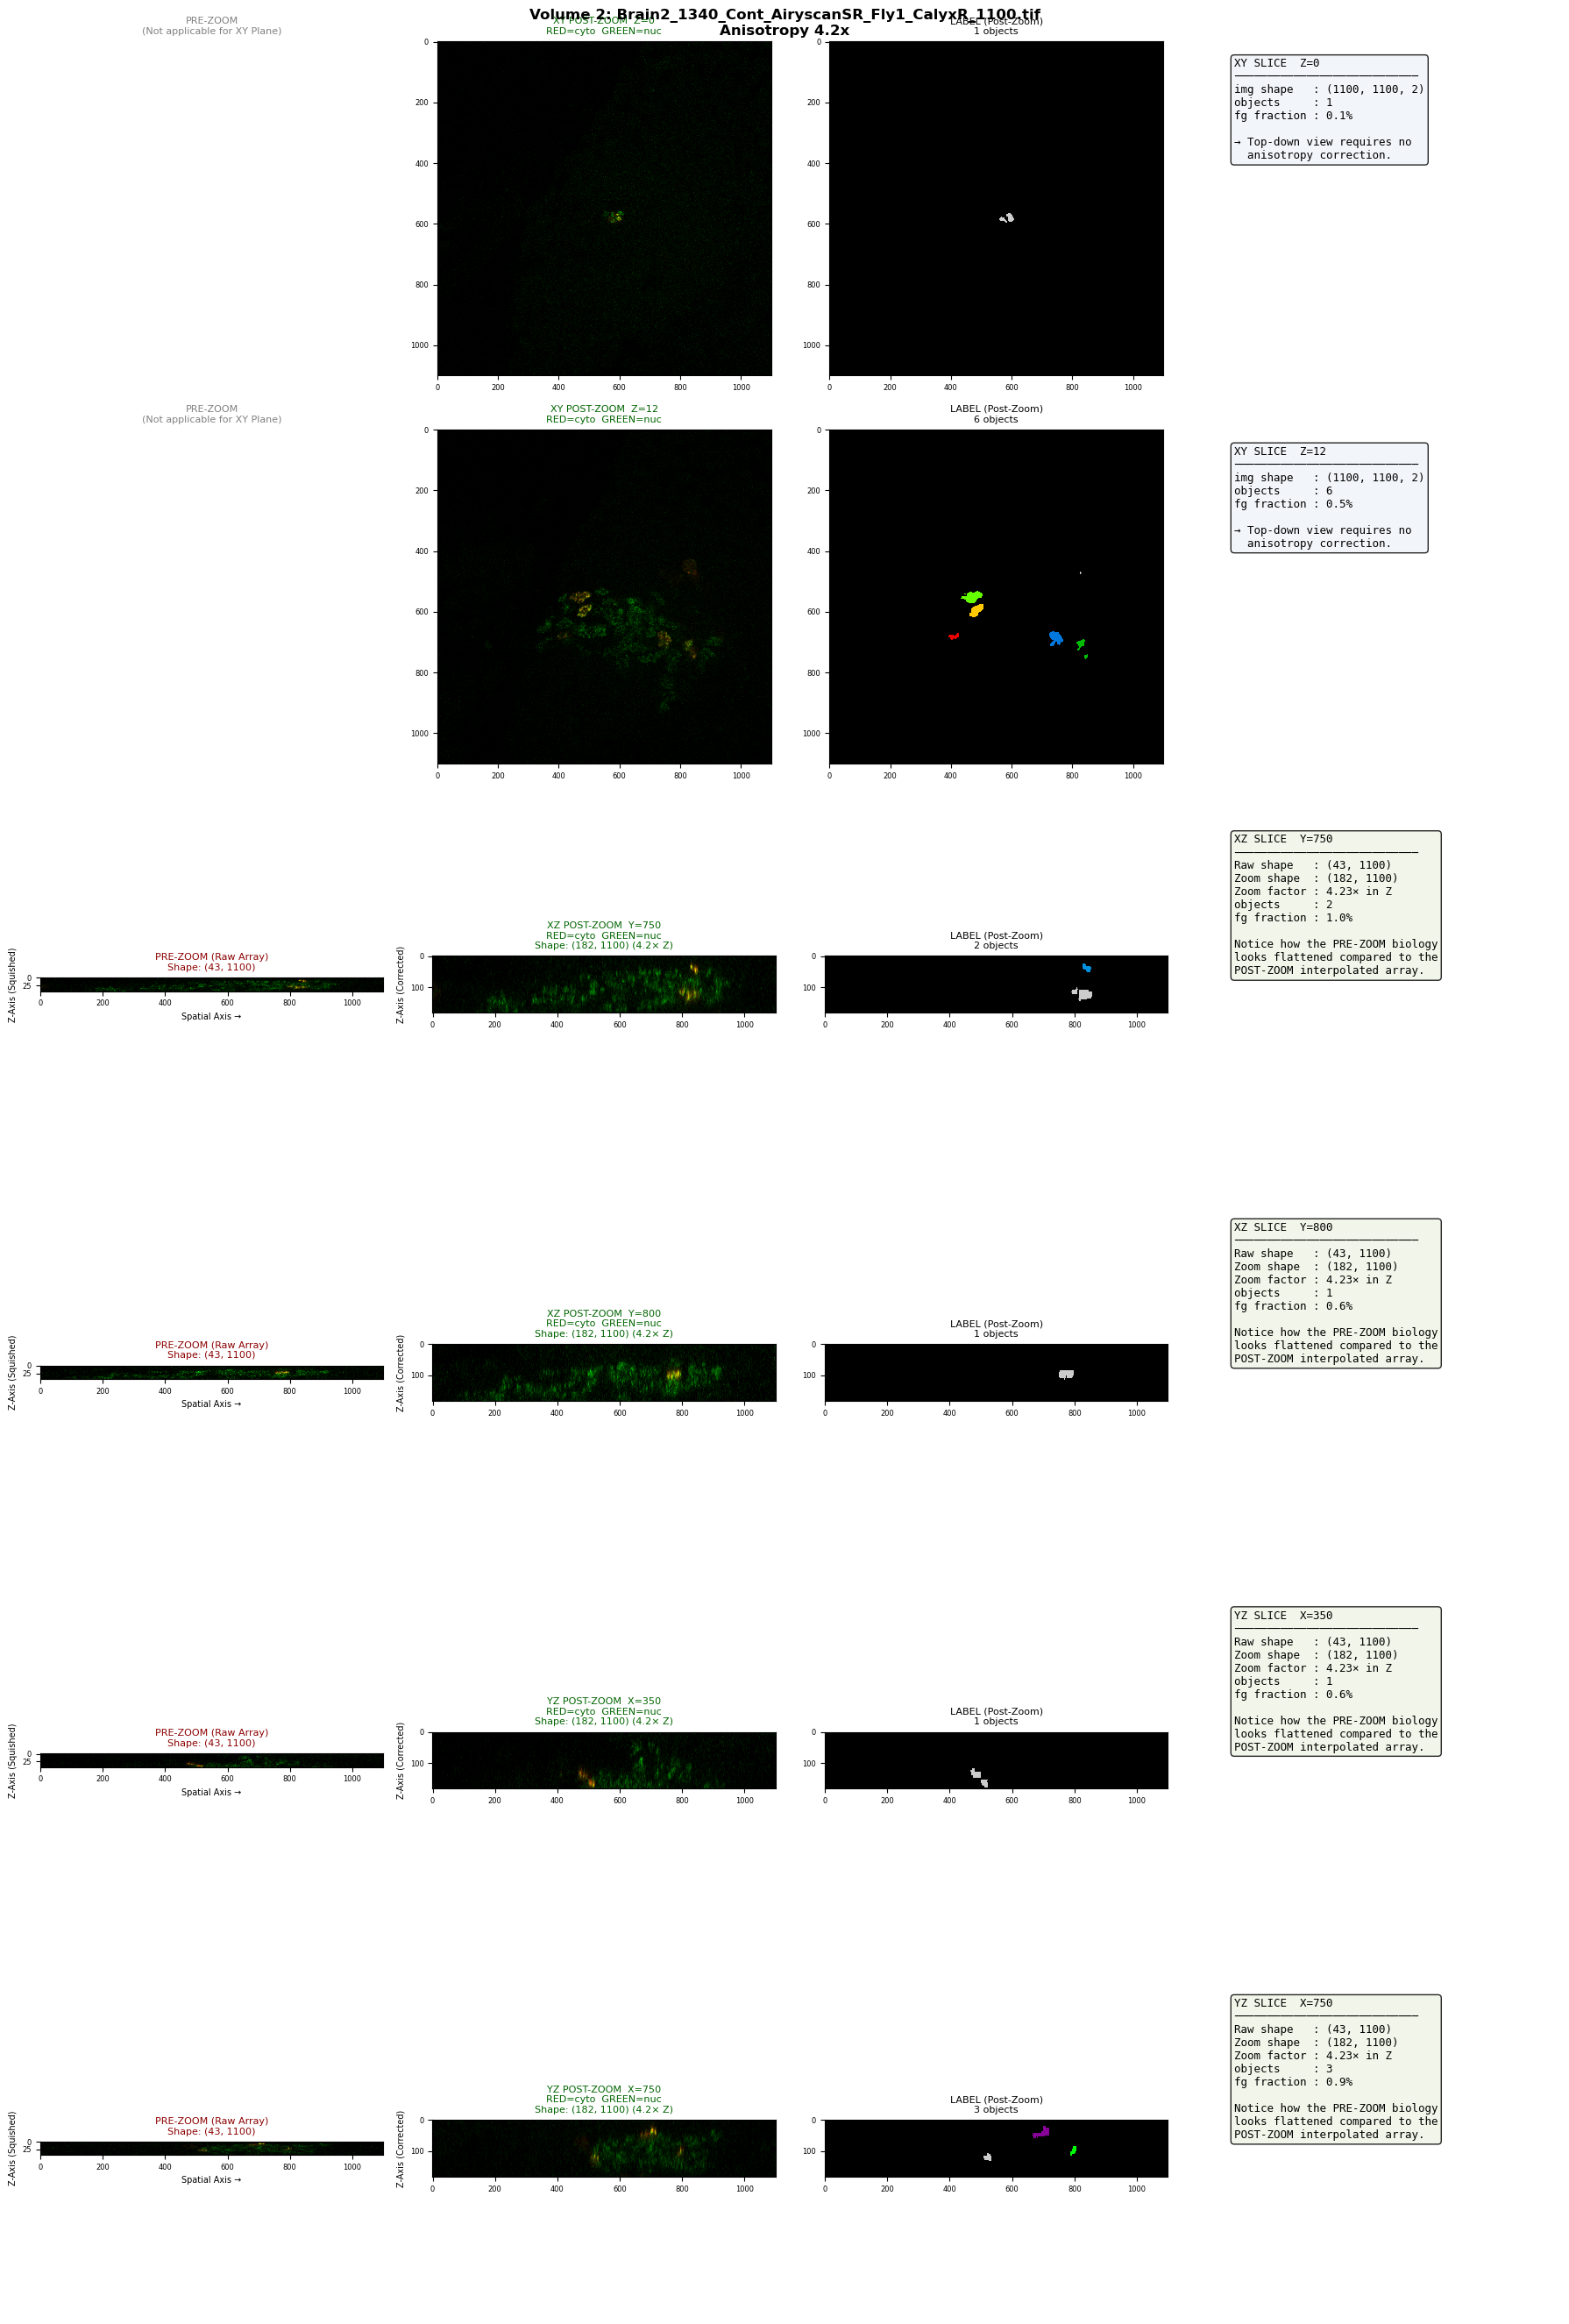

In [13]:
# This runs the same visualization pipeline on the validation data
visualize_cellpose3d_pipeline(
    val_raw, 
    val_lbl, 
    CELLPOSE_CONFIG, 
    num_volumes=2, 
    xy_slices=2, 
    xz_slices=2, 
    yz_slices=2
)